In [5]:
# needed when using ssh connection (?)
#%pip install tensorboard
#%pip install numpy
#%pip install torch
#%pip install matplotlib
#%pip install os

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.utils.tensorboard import SummaryWriter

In [27]:
cwd = os.getcwd()

ssh_connected = 0 # change to 1 if connected to supercomputer

if ssh_connected == 0:
    num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
elif ssh_connected ==1:
    num_csvs = len(os.listdir("/home/astrouser/sean/Eclipsing Binaries/Data/ELISa lightcurve data"))
    
fluxes_array = np.empty((0, 100))  # initialize fluxes_array to empty, will be replaced with first light curve
phases_array = np.empty((0,100)) # same for phases 

EB_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 
fluxes = np.array([])
phases = np.array([])
param_names = ["T_ratio", "T1", "q", "m1", "period", "Omega1", "Omega2", "e"]
    
T1 = []     # set empty lists for parameters
T_ratio = []
q = []
m1 = []
period = []
Omega1 = []
Omega2 = []
e = []


params_1000 = {} # create empty dictionary for parameter list contianing 1000 values

for name in param_names: # loop through parameter names, adding their values to their name in the dictionary
    params_1000[name] = np.loadtxt(
        os.path.join(cwd, "Data", "ELISa synthetic parameters", f"{name}.csv"),
        delimiter=',',
        skiprows=0
    )

params = {} # create empty disct for correct number of param values

for name in param_names:
    # give empty dictionary correct keys
    params[name]=[]



# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(0, 4*num_csvs): # using 4 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        phases = data[:, 0]
        fluxes = data[:, 1]
        label = EB_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)


        for name in param_names:
            # insert only the parameters of the systems that are used into the new one - so that the system number for parameters matches with fluxes.
            params[name].append(params_1000[name][i])


        if fluxes_array.size < 1: # set up array with the first light curve. Will only trigger on first iteration due to np.empty
            fluxes_array = fluxes
        else: # add the next light curve to a 2d array of light curves
            fluxes_array = np.vstack((fluxes_array, fluxes))

        if phases_array.size < 1: # set up first phases into phases_array
            phases_array = phases
        else: # stack the next set of phases into a new line in the 2d array of phases
            phases_array = np.vstack((phases_array, phases))

    else:
        continue



In [92]:
# creating phase offset parameter, intended to model the synthetic data moer as realistic data, and to be predicted as a parameter in itself
print(phases_array.shape)

# at the moment, each phases_array is a 2d array, with 1000 rows (one for each system), each with 100 data points. 
# these data points are always 0.00 to 0.99, increasing by 0.01, for a totla of 100 data points.
# the goal of offsetting the phases is to make the data more like realistic observations,
# where the eclipse minimum does not always occur at exactly the same phase, as is happening here.

# the goal: add an offset to the phases. however, the range of phases should still be 0-0.99
# for each system, generate a range of 100 points, all from 

offsets = np.array([]) # initialise empty array to save offsets for parameter prediction

for i in range(phases_array.shape[0]): # loop through every stellar model system:
    offset_index = np.random.randint(0,99) # generate a random offset from 0-99
    offsets += offset_index # save the index of the offset
    phases_a = phases_array[i][offset_index:] # slice the currently iterated phases array FROM offset_index
    phases_b = phases_array[i][:offset_index] # slice the currently iterated phases array UNTIL offset_index
    phases_array[i] = np.concatenate((phases_a,phases_b)) # now combined the two above, so that the array is still 0 - 0.99, but now has a random start point

print(phases_array[i])

(1000, 100)
[0.65 0.66 0.67 0.68 0.69 0.7  0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78
 0.79 0.8  0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92
 0.93 0.94 0.95 0.96 0.97 0.98 0.99 0.   0.01 0.02 0.03 0.04 0.05 0.06
 0.07 0.08 0.09 0.1  0.11 0.12 0.13 0.14 0.15 0.16 0.17 0.18 0.19 0.2
 0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29 0.3  0.31 0.32 0.33 0.34
 0.35 0.36 0.37 0.38 0.39 0.4  0.41 0.42 0.43 0.44 0.45 0.46 0.47 0.48
 0.49 0.5  0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59 0.6  0.61 0.62
 0.63 0.64]


In [8]:
# sanity check cell

print(fluxes_array.shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(len(params['T_ratio']))


(1000, 100)
1001
(1000,)
1000


In [9]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cpu


In [10]:
rel = fluxes_array / fluxes_array.mean(axis=1, keepdims=True) - 1.0
rel = rel / rel.std()

light_curves_tensor = torch.tensor(rel, dtype=torch.float32)
light_curve_labels = torch.tensor(labels, dtype=torch.long)

params_tensor = torch.tensor(
    # stack parameters into one tensor with shape (N, 8), with N: the system number, and the 8 being each parameteer value for that system
    np.stack([params[name] for name in param_names], axis=1), dtype=torch.float32)

In [11]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_array.shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_array.shape[0])

full_dataset = TensorDataset(light_curves_tensor, light_curve_labels, params_tensor)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_params = params_tensor[train_dataset.indices]
p_mean = train_params.mean(dim=0).to(device) # mean of each parameter. a tensor of shape (8)
p_std = train_params.std(dim=0).to(device) # std of each parameter. these will be used to normalise the parameters later

# Loading training and validation data into DataLoader for batching
batch_size = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()  # Initialize TensorBoard writer

In [ ]:
print(len(train_loader.dataset), len(val_loader.dataset))

800


In [13]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [14]:
# simplified cnn, not resnet:

def length(length, kernel_size, stride):
    return ((length - kernel_size) // stride) + 1

class CNN(nn.Module):
    def __init__(self, n_classes=2, n_params=8):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=7, stride=2,padding=3)
        self.pool = nn.AvgPool1d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, stride=2,padding=2)
        self.conv3 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=5, stride=2,padding=2)

        self.sharedfc = nn.Sequential(nn.Linear(256 * 3, 128),nn.ReLU()) # shared output node for two outputs
        self.cls_head = nn.Linear(128, n_classes) # output head for classification (detached vs overcontact)
        self.rgs_head = nn.Linear(128, n_params) # output head for parameters (regression)

# cnn conv layer length formula: ((length - kernel_size) / stride){rounded down} + 1
# size: (batch_size, channels, length)



    def forward(self, x): # input size: (batch_size, 100)
        x = x.unsqueeze(1)         # (batch_size, 2, 100)
        x = F.relu(self.conv1(x))   # (batch_size, 64, 50)
        x = self.pool(x)            # (batch_size, 64, 25)
        x = F.relu(self.conv2(x))   # (batch_size, 128, 13)
        x = self.pool(x)            # (batch_size, 128, 6)
        x = F.relu(self.conv3(x))   # (batch_size, 256, 3)
        x = x.reshape(x.size(0), -1) # Flatten the tensor to (batch_size, 256 * length) 
        x = self.sharedfc(x)
        
        return self.cls_head(x), self.rgs_head(x) # two outputs

In [15]:
# hyperparameters!

lr = 0.001
epochs = 1000
batch_size = 10

In [16]:
# early stop criteria:
patience = 100
delta = 0.01
best_val_loss = float("inf")
no_improvement_count = 0

class EarlyStopping:
    def __init__(self, patience=10, delta=0.01, verbose=False):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.best_loss = None
        self.no_improvement_count = 0
        self.stop_training = False

    def check_early_stop(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1
            if self.no_improvement_count >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print(f"Stop early due to no improvement")

# now initialise it:
early_stopping = EarlyStopping(patience=patience, delta=delta, verbose=True)


In [17]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
C_criterion = nn.CrossEntropyLoss() # classification criterion
R_criterion = nn.MSELoss() # regression criterion


W_rgs = 1.0 # weighting of regression task against classification

loss, val_loss, val_accuracy = [], [], []
train_losses, val_losses, val_C_accuracies, val_R_accuracies = [], [], [], []

param_mse_array, param_mae_array = np.zeros((0,8)),np.zeros((0,8)) # initialising empty arrays to store parameter errors later


train_C_losses, train_R_losses = [], []
for epoch in range(epochs):
    val_accuracy = 0
    model.train()
    train_loss=0
    train_C_loss, train_R_loss = 0,0
    # initialise tensors to store individual parameter losses:
    R_squared_errors = torch.zeros(8, device=device)
    R_absolute_errors = torch.zeros(8, device=device)
    for inputs, cls_labels, param_targets in train_loader:
        inputs = inputs.to(device)  # Move inputs to the same device as the model
        cls_labels = cls_labels.to(device)
        param_targets = (param_targets.to(device) - p_mean) / p_std # normalising! as otherwise it would be dominated by high parameters e.g. temperature


        optimizer.zero_grad() # set gradients to zero
        cls_out, rgs_out = model(inputs) # forward pass both outputs
        C_loss = C_criterion(cls_out, cls_labels) # calculate loss for classification based on predictions and true labels
        R_loss = R_criterion(rgs_out, param_targets) # loss for regression taks, based on predictions and (normalised) param labels


        train_C_loss += C_loss.item() # logging individual losses
        train_R_loss += R_loss.item()
        
        loss = C_loss + W_rgs * R_loss # combine losses into one, with weight depending on W_rgs

        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() # accumulate loss for the epoch
       
    train_losses.append(train_loss / len(train_loader))
    train_C_losses.append(train_C_loss / len(train_loader))
    train_R_losses.append(train_R_loss / len(train_loader))
    writer.add_scalar('Training Loss', train_losses[-1], epoch)

# Validation
    model.eval()
    val_loss, C_correct, R_correct =0,0,0
    abs_err = torch.zeros(len(param_names),device=device) # create empty tensor of size (8)

    with torch.no_grad(): # make sure the gradients changed in this step
        for inputs, cls_labels, param_targets in val_loader:
            inputs = inputs.to(device)  # Move inputs to the same device as the model
            cls_labels = cls_labels.to(device)
            param_true = param_targets.to(device) # save the true parameters
            param_norm = (param_true - p_mean) / p_std # save the normalised parameters

            cls_out, rgs_out = model(inputs)


            # Individual parameter squared and absolute errors. tensor of size (8) for each epoch, one for each parameter.
            param_mse = ((rgs_out - param_norm) ** 2).mean(dim=0)
            param_mae = torch.abs(rgs_out - param_norm).mean(dim=0)

            R_squared_errors += param_mse * rgs_out.size(0) # totals up the squared errors for each parameter
            R_absolute_errors += param_mae * rgs_out.size(0) # totals up absolute errors for each parameter. 
            # both above lines are then multiplied by the batch size to get the total error for each parameter across the entire validation set.



            val_loss += (C_criterion(cls_out, cls_labels) + W_rgs * R_criterion(rgs_out, param_norm)).item()

            C_correct += (cls_out.argmax(dim=1) == cls_labels).sum().item()
            R_correct += torch.abs(rgs_out - param_norm).sum().item()

    val_losses.append(val_loss / len(val_loader))
    val_C_accuracies.append(C_correct / len(val_loader.dataset))
    val_R_accuracies.append(R_correct / (len(val_loader.dataset) * rgs_out.shape[1]))
    writer.add_scalar('Validation Loss', val_losses[-1], epoch)

    param_mse = R_squared_errors / len(val_loader.dataset)
    param_mae = R_absolute_errors / len(val_loader.dataset)

    # collect parameter errors for plotting later:
    param_mse_array = np.vstack([param_mse_array,param_mse.cpu().numpy()])
    param_mae_array = np.vstack([param_mae_array, param_mae.cpu().numpy()])

    for name, mse, mae in zip(param_names, param_mse, param_mae):
        print(f"{name:8s} MSE={mse.item():.4f}, MAE={mae.item():.4f}")

    # check for early stopping:
    early_stopping.check_early_stop(val_loss)

    if early_stopping.stop_training:
        print(f"Early stopping triggered at epoch {epoch}.")
        break

    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}")
    print(f"  train C_loss {train_C_loss/len(train_loader):.4f}, R_loss {train_R_loss/len(train_loader):.4f},Val Acc (Classification): {val_C_accuracies[-1]:.4f}, Val MAE (Parameters): {val_R_accuracies[-1]:.4f}")
    #for name, mse, mae in zip(param_names, param_mse, param_mae):
    #    print(f"{name:8s} MSE={mse:.4f}, MAE={mae:.4f}")
# 21.6 seconds for 48 epochs => 0.45 seconds per epoch 

T_ratio  MSE=0.4116, MAE=0.4511
T1       MSE=0.8975, MAE=0.7981
q        MSE=0.7230, MAE=0.6936
m1       MSE=0.8281, MAE=0.7735
period   MSE=0.8402, MAE=0.7770
Omega1   MSE=0.7765, MAE=0.6980
Omega2   MSE=0.8655, MAE=0.7642
e        MSE=0.3567, MAE=0.3886
Epoch 0: Training Loss: 0.9964, Validation Loss: 0.7709
  train C_loss 0.1870, R_loss 0.8094,Val Acc (Classification): 0.9900, Val MAE (Parameters): 0.6680
T_ratio  MSE=0.3692, MAE=0.4258
T1       MSE=0.8770, MAE=0.7960
q        MSE=0.7064, MAE=0.6708
m1       MSE=0.8153, MAE=0.7727
period   MSE=0.8186, MAE=0.7714
Omega1   MSE=0.6834, MAE=0.6713
Omega2   MSE=0.8018, MAE=0.7383
e        MSE=0.2985, MAE=0.3523
Epoch 1: Training Loss: 0.7701, Validation Loss: 0.7119
  train C_loss 0.0575, R_loss 0.7126,Val Acc (Classification): 0.9900, Val MAE (Parameters): 0.6498
T_ratio  MSE=0.3262, MAE=0.3734
T1       MSE=0.8879, MAE=0.7877
q        MSE=0.5993, MAE=0.6257
m1       MSE=0.8100, MAE=0.7750
period   MSE=0.8265, MAE=0.7722
Omega1   MSE=0.5

In [ ]:
# todo plot accuracy - done
# make parameters independent in elisa(m2, T2) - done
# include parameters in network¨
    # correct output neurons - done
    # update data loaders - done
    # 2 loss functions - one for classification (have now), one for regression (MSE) for parameters - done
    # then combine losses - done
    # make the model actually able to predict all parameters - all but T_ratio, period and m1
# begin to add noise, and phase offset (custom dataloader,), predict phase offset as new parameter

# update windows
# click <> in bottom left, click ssh, type ssh astrouser@130.238.192.91, password is astro26
# note: files will not transfer to remote server
# WinSCP - use to copy and paste files between this laptop and remote server

# people who might want ml 
# Anish (if these fail, ask Anish for suggestions)
# Ulrike
# Ishaan Kothiyal (phd student)
# IRF (space physics department)
    # Inaki, Atlas
# ai4physics seminar 

In [19]:
print(param_mse)

tensor([0.4372, 0.5797, 0.1386, 1.3751, 1.2084, 0.2273, 0.2800, 0.0980])


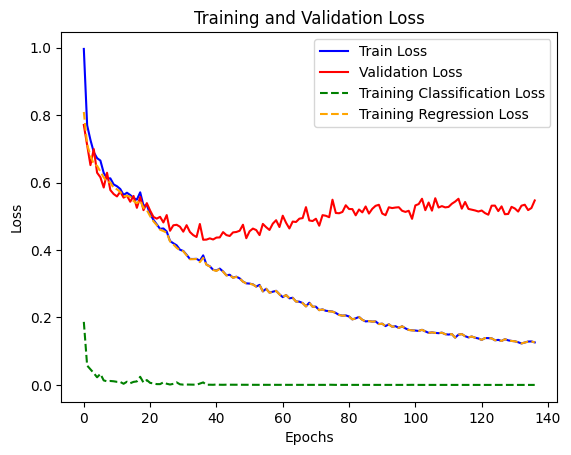

In [20]:
# Plot training/validation loss
plt.figure()
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.plot(train_C_losses, label='Training Classification Loss', color='green',linestyle='dashed')
plt.plot(train_R_losses, label='Training Regression Loss', color='orange',linestyle='dashed')

#plt.plot(val_C_accuracies, label="Validation Classification Accuracy", color="green")
#plt.plot(val_R_accuracies, label="Validation Regression Accuracy", color='orange')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [21]:
# showing beginning and end mse values for each parameter:

for name in param_names:
    print(f"{name:8s} MSE: Start = {param_mse_array[0,param_names.index(name)]}, End = {param_mse_array[-1,param_names.index(name)]}")


for name in param_names:
    print(f"{name:8s} MAE: Start = {param_mae_array[0,param_names.index(name)]}, End = {param_mae_array[-1,param_names.index(name)]}")


# Note: an MSE of 1 means it will always predict the mean, which means the MSE will equal the varience of the parameter (1 for normalised parameters).

T_ratio  MSE: Start = 0.41156005859375, End = 0.4371863603591919
T1       MSE: Start = 0.8975257873535156, End = 0.579692006111145
q        MSE: Start = 0.7229976058006287, End = 0.13855767250061035
m1       MSE: Start = 0.8281410932540894, End = 1.3750941753387451
period   MSE: Start = 0.840171754360199, End = 1.2084459066390991
Omega1   MSE: Start = 0.7765352725982666, End = 0.22726118564605713
Omega2   MSE: Start = 0.8654878735542297, End = 0.28004467487335205
e        MSE: Start = 0.35667216777801514, End = 0.0979849174618721
T_ratio  MAE: Start = 0.4511360228061676, End = 0.3765902817249298
T1       MAE: Start = 0.7980733513832092, End = 0.5834509134292603
q        MAE: Start = 0.6936189532279968, End = 0.2546687126159668
m1       MAE: Start = 0.7734584212303162, End = 0.9499111771583557
period   MAE: Start = 0.7770423889160156, End = 0.8576944470405579
Omega1   MAE: Start = 0.6980351209640503, End = 0.3262142539024353
Omega2   MAE: Start = 0.7641661763191223, End = 0.354380846023

(137, 8)
['T_ratio', 'T1', 'q', 'm1', 'period', 'Omega1', 'Omega2', 'e']


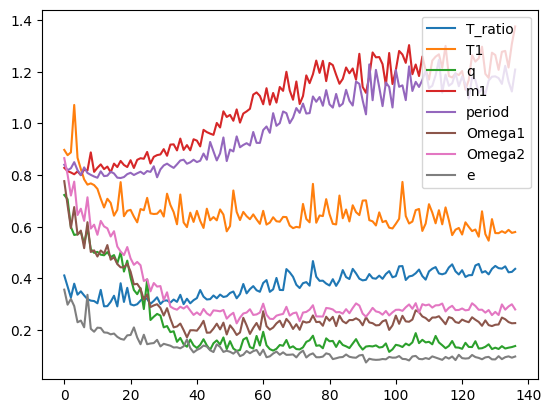

In [22]:
# plotting individual parameter mean squared errors
print(param_mse_array.shape)
print(param_names)

plt.figure()
for i in range(param_mse_array.shape[1]):
    plt.plot(range(param_mse_array.shape[0]), param_mse_array[:,i],label=param_names[i])

plt.legend()

(137, 8)
['T_ratio', 'T1', 'q', 'm1', 'period', 'Omega1', 'Omega2', 'e']


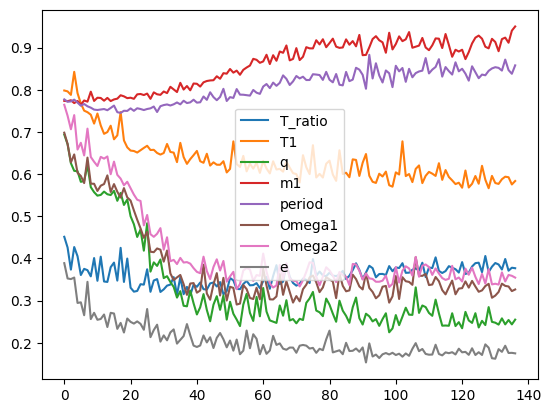

In [23]:
# plotting individual parameter mean absolute errors
print(param_mae_array.shape)
print(param_names)

plt.figure()
for i in range(param_mae_array.shape[1]):
    plt.plot(range(param_mae_array.shape[0]), param_mae_array[:,i],label=param_names[i])

plt.legend()